# Cassava Leaf Disease Classification: Faster MLOps Pipeline

This notebook downloads the Cassava Leaf Disease Classification dataset, explores the images, cleans the labels and file list, trains an EfficientNetB0 transfer-learning model, evaluates it, saves both `.keras` and `.h5` files, and writes reusable Python scripts into `src/`.

**Runtime note:** Training time depends on the hardware. A GPU is strongly recommended. The notebook uses 260×260 images, a smaller backbone, early stopping, parallel image loading and a short fine-tuning stage. Do not expect a fixed training time or guaranteed accuracy.

## 1. Install and import packages

In [18]:
%pip install -q kagglehub tensorflow scikit-learn pandas numpy matplotlib seaborn pillow tqdm

Note: you may need to restart the kernel to use updated packages.


In [19]:
import os, json, random, shutil, sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, UnidentifiedImageError
from tqdm.auto import tqdm

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

GPU_AVAILABLE = bool(tf.config.list_physical_devices("GPU"))
USE_MIXED_PRECISION = GPU_AVAILABLE
keras.mixed_precision.set_global_policy("mixed_float16" if USE_MIXED_PRECISION else "float32")

print("TensorFlow:", tf.__version__)
print("GPU available:", GPU_AVAILABLE)
print("Mixed precision:", USE_MIXED_PRECISION)

TensorFlow: 2.21.0
GPU available: True
Mixed precision: True


## 2. Download the Kaggle dataset

In [20]:
import kagglehub

dataset_path = Path(
    kagglehub.competition_download("cassava-leaf-disease-classification")
)
print("Downloaded to:", dataset_path)
print("Files:", [p.name for p in dataset_path.iterdir()])

Downloaded to: /kaggle/input/competitions/cassava-leaf-disease-classification
Files: ['train_tfrecords', 'sample_submission.csv', 'test_tfrecords', 'label_num_to_disease_map.json', 'train_images', 'train.csv', 'test_images']


In [44]:
dataset_path

PosixPath('/kaggle/input/competitions/cassava-leaf-disease-classification')

In [21]:
TRAIN_CSV = dataset_path / "train.csv"
TRAIN_DIR = dataset_path / "train_images"
TEST_DIR = dataset_path / "test_images"

if not TRAIN_CSV.exists() or not TRAIN_DIR.exists():
    raise FileNotFoundError("Expected train.csv and train_images were not found.")

labels_df = pd.read_csv(TRAIN_CSV)
labels_df["image_id"] = labels_df["image_id"].astype(str)
labels_df["label"] = labels_df["label"].astype(int)
print("Labelled images:", len(labels_df))
display(labels_df.head())

Labelled images: 21397


,image_id,label
0,1000015157.jpg,0
1,1000201771.jpg,3
2,100042118.jpg,1
3,1000723321.jpg,1
4,1000812911.jpg,3


## 3. Clean labels and check image files

In [22]:
CLASS_NAMES = {
    0: "Cassava Bacterial Blight (CBB)",
    1: "Cassava Brown Streak Disease (CBSD)",
    2: "Cassava Green Mottle (CGM)",
    3: "Cassava Mosaic Disease (CMD)",
    4: "Healthy"
}
NUM_CLASSES = len(CLASS_NAMES)

# Remove duplicate rows, missing labels and labels outside the five known classes.
labels_df = labels_df.drop_duplicates(subset=["image_id"]).dropna(subset=["image_id", "label"])
labels_df = labels_df[labels_df["label"].isin(CLASS_NAMES)].copy()
labels_df["label"] = labels_df["label"].astype(int)

# Check file existence. Full image decoding is checked on a sample to avoid
# spending extra time decoding the entire dataset before training.
labels_df["image_path"] = labels_df["image_id"].map(lambda n: str(TRAIN_DIR / n))
labels_df = labels_df[labels_df["image_path"].map(lambda p: Path(p).is_file())].reset_index(drop=True)

print("Usable labelled images:", len(labels_df))
print("Missing files removed:", len(pd.read_csv(TRAIN_CSV)) - len(labels_df))
display(labels_df["label"].map(CLASS_NAMES).value_counts().to_frame("image_count"))

Usable labelled images: 21397
Missing files removed: 0


,image_count
label,
Cassava Mosaic Disease (CMD),13158
Healthy,2577
Cassava Green Mottle (CGM),2386
Cassava Brown Streak Disease (CBSD),2189
Cassava Bacterial Blight (CBB),1087


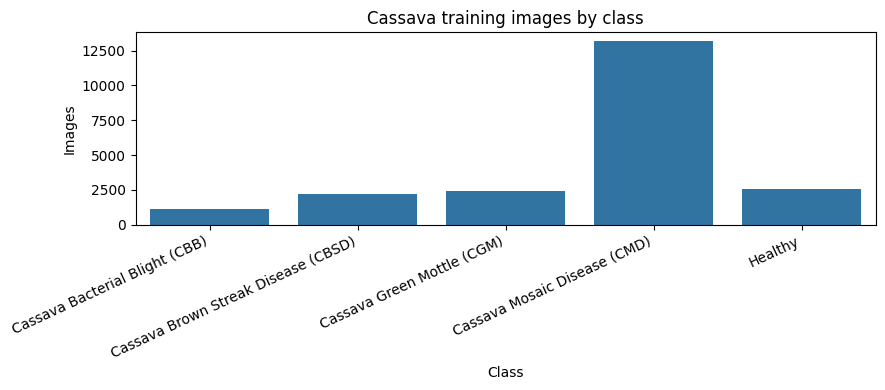

In [23]:
class_counts = labels_df["label"].value_counts().sort_index()
plt.figure(figsize=(9, 4))
sns.barplot(x=[CLASS_NAMES[i] for i in class_counts.index], y=class_counts.values)
plt.title("Cassava training images by class")
plt.xlabel("Class")
plt.ylabel("Images")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

## 4. Exploratory Data Analysis (EDA): inspect the leaf images

Images are the main data in this project, so looking at them is important. We will:
- display examples from all five disease classes;
- compare the number of images in each class;
- inspect image width and height on a sample;
- look at simple visual features such as brightness, contrast and green-channel intensity.

These checks help us spot class imbalance, image-size differences and visible patterns. The model still learns from the full images, not only these simple features.

## 4. Inspect images and image dimensions

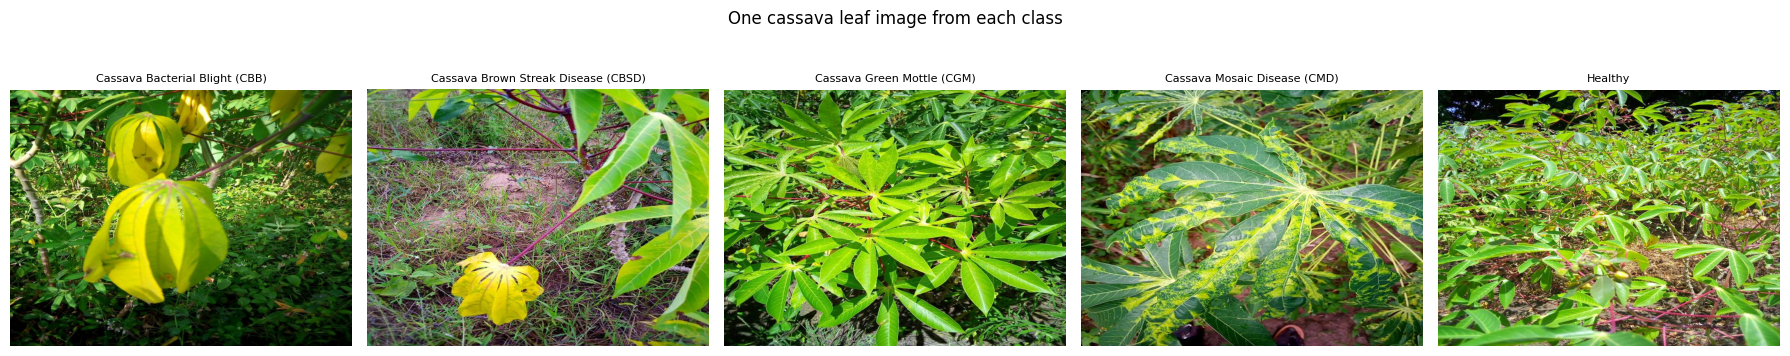

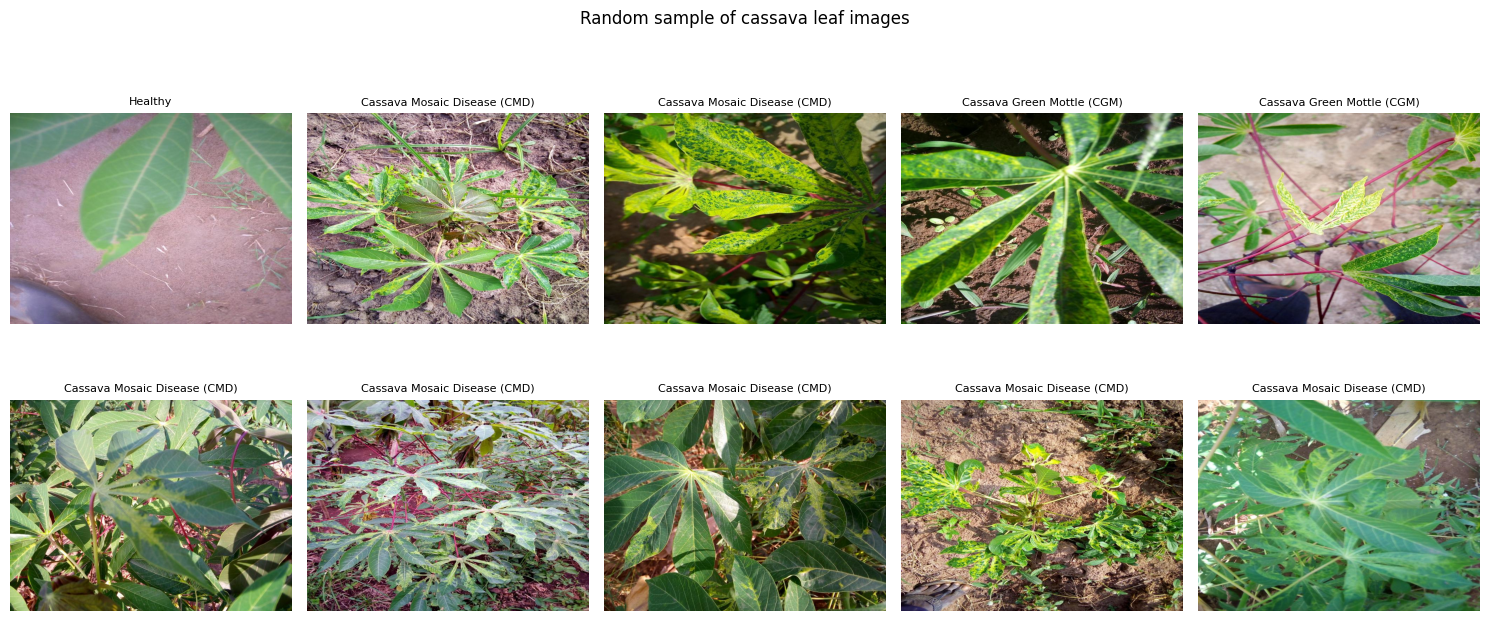

Sampled image widths: 800 to 800 pixels
Sampled image heights: 600 to 600 pixels


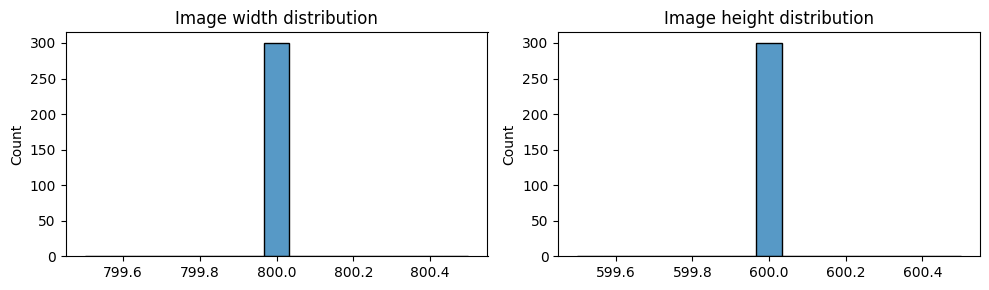

In [24]:
# Display one image from each class, then a larger random sample.
fig, axes = plt.subplots(1, NUM_CLASSES, figsize=(18, 4))
for class_id, ax in enumerate(axes):
    class_rows = labels_df[labels_df.label == class_id]
    row = class_rows.sample(1, random_state=SEED).iloc[0]
    with Image.open(TRAIN_DIR / row.image_id) as image:
        ax.imshow(image.convert("RGB"))
    ax.set_title(CLASS_NAMES[class_id], fontsize=8)
    ax.axis("off")
plt.suptitle("One cassava leaf image from each class")
plt.tight_layout()
plt.show()

# A second grid makes it easier to see variation within the classes.
eda_sample = labels_df.sample(min(10, len(labels_df)), random_state=SEED)
fig, axes = plt.subplots(2, 5, figsize=(15, 7))
for ax, row in zip(axes.flat, eda_sample.itertuples(index=False)):
    with Image.open(TRAIN_DIR / row.image_id) as image:
        ax.imshow(image.convert("RGB"))
    ax.set_title(CLASS_NAMES[int(row.label)], fontsize=8)
    ax.axis("off")
for ax in axes.flat[len(eda_sample):]:
    ax.axis("off")
plt.suptitle("Random sample of cassava leaf images")
plt.tight_layout()
plt.show()

# Inspect image dimensions on a small sample to avoid decoding every file twice.
sample_names = labels_df.image_id.sample(min(300, len(labels_df)), random_state=SEED)
sizes = []
for name in sample_names:
    with Image.open(TRAIN_DIR / name) as image:
        sizes.append(image.size)
widths = [w for w, h in sizes]
heights = [h for w, h in sizes]
print(f"Sampled image widths: {min(widths)} to {max(widths)} pixels")
print(f"Sampled image heights: {min(heights)} to {max(heights)} pixels")

fig, axes = plt.subplots(1, 2, figsize=(10, 3))
sns.histplot(widths, bins=15, ax=axes[0])
axes[0].set_title("Image width distribution")
sns.histplot(heights, bins=15, ax=axes[1])
axes[1].set_title("Image height distribution")
plt.tight_layout()
plt.show()

## 5. Create stratified training and validation sets

In [25]:
train_df, val_df = train_test_split(
    labels_df[["image_id", "label"]],
    test_size=0.20,
    random_state=SEED,
    stratify=labels_df["label"]
)
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
print("Training images:", len(train_df))
print("Validation images:", len(val_df))

Training images: 17117
Validation images: 4280


## 6. Fast image preprocessing pipeline

In [26]:
# Smaller images and a lighter backbone reduce compute cost.
IMAGE_SIZE = (260, 260)
BATCH_SIZE = 32 if GPU_AVAILABLE else 16
AUTOTUNE = tf.data.AUTOTUNE
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebook":
    PROJECT_ROOT = PROJECT_ROOT.parent

MODEL_DIR = PROJECT_ROOT / "models"
REPORT_DIR = PROJECT_ROOT / "reports"
SRC_DIR = PROJECT_ROOT / "src"
for folder in (MODEL_DIR, REPORT_DIR, SRC_DIR):
    folder.mkdir(parents=True, exist_ok=True)
os.chdir(PROJECT_ROOT)  # %%writefile cells below will write into the project root

KERAS_MODEL_PATH = MODEL_DIR / "cassava_leaf_model.keras"
H5_MODEL_PATH = MODEL_DIR / "cassava_leaf_model.h5"

# EfficientNetB0 includes its own input rescaling. Supply RGB pixels in the 0-255 range.
def decode_image(path):
    image_bytes = tf.io.read_file(path)
    image = tf.io.decode_jpeg(image_bytes, channels=3)
    image = tf.image.resize(image, IMAGE_SIZE, antialias=False)
    return tf.cast(image, tf.float32)

def build_dataset(frame, training=False):
    paths = [str(TRAIN_DIR / name) for name in frame.image_id]
    labels = frame.label.astype("int32").to_numpy()
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        ds = ds.shuffle(len(frame), seed=SEED, reshuffle_each_iteration=True)

    def load(path, label):
        image = decode_image(path)
        return image, tf.one_hot(label, NUM_CLASSES)

    ds = ds.map(load, num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = build_dataset(train_df, training=True)
val_ds = build_dataset(val_df)
val_sparse_ds = tf.data.Dataset.from_tensor_slices((
    [str(TRAIN_DIR / n) for n in val_df.image_id],
    val_df.label.astype("int32").to_numpy()
)).map(lambda p, y: (decode_image(p), y), num_parallel_calls=AUTOTUNE).batch(BATCH_SIZE).prefetch(AUTOTUNE)

print("Image size:", IMAGE_SIZE, "| Batch size:", BATCH_SIZE)

Image size: (260, 260) | Batch size: 32


## 13. Create the reusable Python files in `src/`

Run the following cells to write the Python modules into the project's `src/` folder. The files use the same 260 × 260 input size and EfficientNetB0 model as this notebook.

In [27]:
%%writefile src/__init__.py
"""Cassava disease MLOps source package."""

Overwriting src/__init__.py


In [28]:
%%writefile src/config.py
from pathlib import Path

PROJECT_ROOT = Path(__file__).resolve().parents[1]
MODEL_DIR = PROJECT_ROOT / "models"
DATA_DIR = PROJECT_ROOT / "data"
RETRAIN_DIR = DATA_DIR / "retrain"
IMAGE_SIZE = (260, 260)
NUM_CLASSES = 5
CLASS_NAMES = {
    0: "Cassava Bacterial Blight (CBB)",
    1: "Cassava Brown Streak Disease (CBSD)",
    2: "Cassava Green Mottle (CGM)",
    3: "Cassava Mosaic Disease (CMD)",
    4: "Healthy",
}
KERAS_MODEL_PATH = MODEL_DIR / "cassava_leaf_model.keras"
H5_MODEL_PATH = MODEL_DIR / "cassava_leaf_model.h5"

Overwriting src/config.py


In [29]:
%%writefile src/preprocessing.py
from pathlib import Path
import numpy as np
import tensorflow as tf
from PIL import Image
from .config import IMAGE_SIZE

def preprocess_image(image_path):
    """Read an image as RGB and return a float32 batch in the 0-255 range."""
    image = Image.open(image_path).convert("RGB").resize(
        (IMAGE_SIZE[1], IMAGE_SIZE[0]), Image.Resampling.BILINEAR
    )
    array = np.asarray(image, dtype=np.float32)
    return np.expand_dims(array, axis=0)

def decode_path(path, label):
    raw = tf.io.read_file(path)
    image = tf.io.decode_image(raw, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMAGE_SIZE, antialias=False)
    return tf.cast(image, tf.float32), label

Overwriting src/preprocessing.py


In [30]:
%%writefile src/datacleaning.py
from pathlib import Path
from PIL import Image, UnidentifiedImageError
from .config import CLASS_NAMES

VALID_EXTENSIONS = {".jpg", ".jpeg", ".png"}

def validate_image_folder(folder, require_class_folders=True):
    """Check class-folder uploads and return a report; does not delete files."""
    folder = Path(folder)
    report = {"valid": [], "invalid": [], "unknown_folders": []}
    if not folder.exists():
        raise FileNotFoundError(folder)

    if require_class_folders:
        for class_dir in folder.iterdir():
            if not class_dir.is_dir():
                continue
            if class_dir.name not in CLASS_NAMES.values():
                report["unknown_folders"].append(class_dir.name)
                continue
            for path in class_dir.rglob("*"):
                if not path.is_file():
                    continue
                if path.suffix.lower() not in VALID_EXTENSIONS:
                    report["invalid"].append((str(path), "unsupported extension"))
                    continue
                try:
                    with Image.open(path) as im:
                        im.verify()
                    report["valid"].append(str(path))
                except (UnidentifiedImageError, OSError, ValueError) as exc:
                    report["invalid"].append((str(path), str(exc)))
    else:
        for path in folder.rglob("*"):
            if path.is_file():
                try:
                    with Image.open(path) as im:
                        im.verify()
                    report["valid"].append(str(path))
                except Exception as exc:
                    report["invalid"].append((str(path), str(exc)))
    return report

if __name__ == "__main__":
    import argparse
    parser = argparse.ArgumentParser(description="Validate uploaded cassava images")
    parser.add_argument("folder")
    args = parser.parse_args()
    result = validate_image_folder(args.folder)
    print("Valid:", len(result["valid"]))
    print("Invalid:", len(result["invalid"]))
    print("Unknown class folders:", result["unknown_folders"])
    for item in result["invalid"]:
        print("INVALID:", item)

Overwriting src/datacleaning.py


In [31]:
%%writefile src/model.py
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from .config import IMAGE_SIZE, NUM_CLASSES, KERAS_MODEL_PATH

def build_model(weights="imagenet"):
    base = keras.applications.EfficientNetB0(
        include_top=False, weights=weights,
        input_shape=(*IMAGE_SIZE, 3)
    )
    base.trainable = False
    inputs = keras.Input(shape=(*IMAGE_SIZE, 3), name="leaf_image")
    x = layers.RandomFlip("horizontal_and_vertical")(inputs)
    x = layers.RandomRotation(0.08)(x)
    x = layers.RandomZoom(0.10)(x)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.30)(x)
    x = layers.Dense(128, activation="relu",
                     kernel_regularizer=keras.regularizers.l2(1e-4))(x)
    x = layers.Dropout(0.20)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax", dtype="float32")(x)
    return keras.Model(inputs, outputs, name="cassava_efficientnetb0")

def load_model(model_path=KERAS_MODEL_PATH, compile=False):
    return keras.models.load_model(model_path, compile=compile)

Overwriting src/model.py


In [32]:
%%writefile src/prediction.py
import argparse
import numpy as np
from .config import CLASS_NAMES, KERAS_MODEL_PATH
from .model import load_model
from .preprocessing import preprocess_image

def predict_image(image_path, model=None):
    model = model or load_model(KERAS_MODEL_PATH, compile=False)
    batch = preprocess_image(image_path)
    probabilities = model.predict(batch, verbose=0)[0]
    predicted_id = int(np.argmax(probabilities))
    return {
        "class_id": predicted_id,
        "class_name": CLASS_NAMES[predicted_id],
        "confidence": float(probabilities[predicted_id]),
        "probabilities": {
            CLASS_NAMES[i]: float(probabilities[i])
            for i in range(len(CLASS_NAMES))
        }
    }

if __name__ == "__main__":
    parser = argparse.ArgumentParser()
    parser.add_argument("image", help="Path to one leaf image")
    args = parser.parse_args()
    print(predict_image(args.image))

Overwriting src/prediction.py


In [33]:
%%writefile src/retrain.py
import argparse
from pathlib import Path
import tensorflow as tf
from tensorflow import keras
from .config import (
    IMAGE_SIZE, NUM_CLASSES, CLASS_NAMES, KERAS_MODEL_PATH,
    H5_MODEL_PATH, MODEL_DIR
)
from .datacleaning import validate_image_folder

def retrain(data_dir, epochs=3, batch_size=16, validation_split=0.2):
    """
    Retrain the saved model using new labelled images.

    Expected upload layout:
      data/retrain/
        Cassava Bacterial Blight (CBB)/
        Cassava Brown Streak Disease (CBSD)/
        Cassava Green Mottle (CGM)/
        Cassava Mosaic Disease (CMD)/
        Healthy/

    Uploading data does not start training by itself. Run this function or
    its CLI command to trigger retraining after the upload and validation.
    """
    data_dir = Path(data_dir)
    report = validate_image_folder(data_dir)
    if report["invalid"] or report["unknown_folders"]:
        raise ValueError(
            f"Fix invalid images/unknown folders first. "
            f"Invalid={len(report['invalid'])}, unknown={report['unknown_folders']}"
        )
    if len(report["valid"]) < 10:
        raise ValueError("At least 10 valid labelled images are required for retraining.")

    ds = keras.utils.image_dataset_from_directory(
        data_dir,
        labels="inferred",
        label_mode="categorical",
        class_names=[CLASS_NAMES[i] for i in range(NUM_CLASSES)],
        image_size=IMAGE_SIZE,
        batch_size=batch_size,
        validation_split=validation_split,
        subset="training",
        seed=42,
        shuffle=True
    )
    val_ds = keras.utils.image_dataset_from_directory(
        data_dir,
        labels="inferred",
        label_mode="categorical",
        class_names=[CLASS_NAMES[i] for i in range(NUM_CLASSES)],
        image_size=IMAGE_SIZE,
        batch_size=batch_size,
        validation_split=validation_split,
        subset="validation",
        seed=42,
        shuffle=True
    )
    autotune = tf.data.AUTOTUNE
    ds = ds.prefetch(autotune)
    val_ds = val_ds.prefetch(autotune)

    if not KERAS_MODEL_PATH.exists():
        raise FileNotFoundError(f"Pre-trained model not found: {KERAS_MODEL_PATH}")
    model = keras.models.load_model(KERAS_MODEL_PATH, compile=False)

    # Fine-tune only the last layers of the existing pre-trained model.
    base = next(layer for layer in model.layers if isinstance(layer, keras.Model))
    base.trainable = True
    for layer in base.layers[:-25]:
        layer.trainable = False
    for layer in base.layers:
        if isinstance(layer, keras.layers.BatchNormalization):
            layer.trainable = False

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-5),
        loss=keras.losses.CategoricalCrossentropy(label_smoothing=0.05),
        metrics=["accuracy"]
    )
    callbacks = [
        keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=2, restore_best_weights=True
        )
    ]
    history = model.fit(
        ds, validation_data=val_ds, epochs=epochs, callbacks=callbacks
    )
    MODEL_DIR.mkdir(parents=True, exist_ok=True)
    model.save(str(KERAS_MODEL_PATH))
    model.save(str(H5_MODEL_PATH))
    print("Updated model saved:", KERAS_MODEL_PATH)
    print("Updated H5 copy saved:", H5_MODEL_PATH)
    return history

if __name__ == "__main__":
    parser = argparse.ArgumentParser(description="Trigger cassava model retraining")
    parser.add_argument("--data", default="data/retrain", help="Uploaded labelled image folder")
    parser.add_argument("--epochs", type=int, default=3)
    parser.add_argument("--batch-size", type=int, default=16)
    args = parser.parse_args()
    retrain(args.data, epochs=args.epochs, batch_size=args.batch_size)

Overwriting src/retrain.py


## 7. Create the model using transfer learning

We use EfficientNetB0 because it is lighter than EfficientNetV2S and is widely supported by TensorFlow/Keras.

**Compatibility note:** `tf.keras.applications.EfficientNetB0()` does not accept the `include_preprocessing` argument in many TensorFlow versions. The notebook therefore leaves that argument out. EfficientNetB0 includes its own input rescaling layer, so the image pipeline supplies RGB pixel values in the 0–255 range.

In [34]:
BACKBONE_NAME = "EfficientNetB0"

def build_model(weights="imagenet"):
    base = keras.applications.EfficientNetB0(
        include_top=False,
        weights=weights,
        input_shape=(*IMAGE_SIZE, 3),
    )
    base.trainable = False

    inputs = keras.Input(shape=(*IMAGE_SIZE, 3), name="leaf_image")
    x = layers.RandomFlip("horizontal_and_vertical")(inputs)
    x = layers.RandomRotation(0.08)(x)
    x = layers.RandomZoom(0.10)(x)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.30)(x)
    x = layers.Dense(128, activation="relu",
                     kernel_regularizer=keras.regularizers.l2(1e-4))(x)
    x = layers.Dropout(0.20)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax", dtype="float32")(x)
    return keras.Model(inputs, outputs, name="cassava_efficientnetb0")

model = build_model()
model.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "cassava_efficientnetb0"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ leaf_image (InputLayer)         │ (None, 260, 260, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 260, 260, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 260, 260, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 260, 260, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 9, 9, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,214,184 (16.08 MB)

 Trainable params: 164,613 (643.02 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

## 8. Train the classification head

In [35]:
def training_callbacks(patience=2):
    return [
        keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=patience,
            restore_best_weights=True, verbose=1
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss", factor=0.3, patience=1,
            min_lr=1e-7, verbose=1
        )
    ]

loss_fn = keras.losses.CategoricalCrossentropy(label_smoothing=0.05)
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss=loss_fn,
    metrics=["accuracy"]
)

HEAD_EPOCHS = 4
head_history = model.fit(
    train_ds, validation_data=val_ds, epochs=HEAD_EPOCHS,
    callbacks=training_callbacks(patience=2)
)

Epoch 1/4
535/535 ━━━━━━━━━━━━━━━━━━━━ 83s 121ms/step - accuracy: 0.6929 - loss: 0.9573 - val_accuracy: 0.7271 - val_loss: 0.8795 - learning_rate: 0.0010
Epoch 2/4
535/535 ━━━━━━━━━━━━━━━━━━━━ 0s 89ms/step - accuracy: 0.7171 - loss: 0.9037
Epoch 2: ReduceLROnPlateau reducing learning rate to 0.0003000000142492354.
535/535 ━━━━━━━━━━━━━━━━━━━━ 59s 109ms/step - accuracy: 0.7213 - loss: 0.8931 - val_accuracy: 0.7280 - val_loss: 0.9058 - learning_rate: 0.0010
Epoch 3/4
535/535 ━━━━━━━━━━━━━━━━━━━━ 59s 110ms/step - accuracy: 0.7356 - loss: 0.8599 - val_accuracy: 0.7479 - val_loss: 0.8521 - learning_rate: 3.0000e-04
Epoch 4/4
535/535 ━━━━━━━━━━━━━━━━━━━━ 0s 89ms/step - accuracy: 0.7403 - loss: 0.8421
Epoch 4: ReduceLROnPlateau reducing learning rate to 9.000000427477062e-05.
535/535 ━━━━━━━━━━━━━━━━━━━━ 59s 110ms/step - accuracy: 0.7405 - loss: 0.8472 - val_accuracy: 0.7315 - val_loss: 0.8812 - learning_rate: 3.0000e-04
Restoring model weights from the end of the best epoch: 3.


## 9. Fine-tune only the last backbone layers

In [36]:
base_model = next(layer for layer in model.layers if isinstance(layer, keras.Model))
base_model.trainable = True

# Keep most of the pretrained feature extractor frozen.
for layer in base_model.layers[:-25]:
    layer.trainable = False
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss=loss_fn,
    metrics=["accuracy"]
)

FINE_TUNE_EPOCHS = 4
fine_history = model.fit(
    train_ds, validation_data=val_ds, epochs=FINE_TUNE_EPOCHS,
    callbacks=training_callbacks(patience=2)
)

Epoch 1/4
535/535 ━━━━━━━━━━━━━━━━━━━━ 82s 125ms/step - accuracy: 0.7457 - loss: 0.8371 - val_accuracy: 0.7533 - val_loss: 0.8447 - learning_rate: 1.0000e-05
Epoch 2/4
535/535 ━━━━━━━━━━━━━━━━━━━━ 63s 117ms/step - accuracy: 0.7587 - loss: 0.8140 - val_accuracy: 0.7617 - val_loss: 0.8134 - learning_rate: 1.0000e-05
Epoch 3/4
535/535 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step - accuracy: 0.7574 - loss: 0.8073
Epoch 3: ReduceLROnPlateau reducing learning rate to 2.9999999242136253e-06.
535/535 ━━━━━━━━━━━━━━━━━━━━ 62s 116ms/step - accuracy: 0.7596 - loss: 0.7998 - val_accuracy: 0.7600 - val_loss: 0.8180 - learning_rate: 1.0000e-05
Epoch 4/4
535/535 ━━━━━━━━━━━━━━━━━━━━ 62s 117ms/step - accuracy: 0.7671 - loss: 0.7899 - val_accuracy: 0.7626 - val_loss: 0.8079 - learning_rate: 3.0000e-06
Restoring model weights from the end of the best epoch: 4.


## 10. Plot training curves

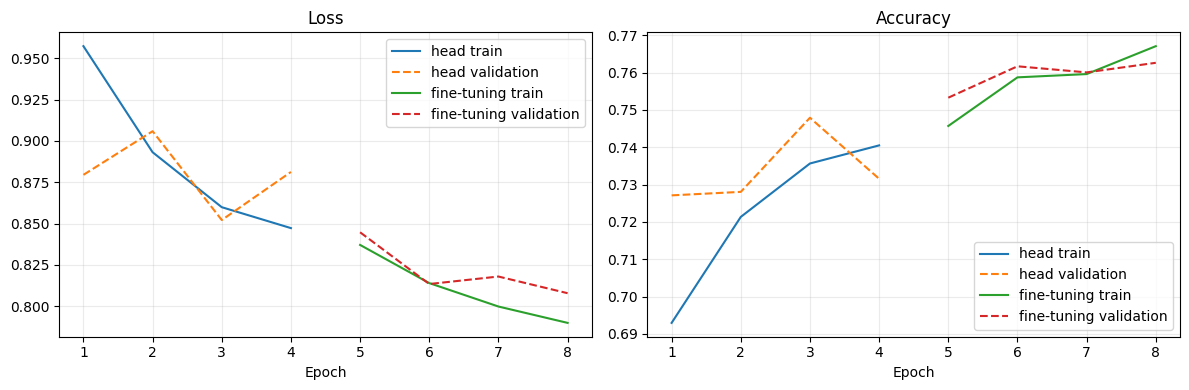

In [37]:
def plot_training_curves(histories):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    offset = 0
    for phase, history in histories:
        h = history.history
        epochs = np.arange(1, len(h["loss"]) + 1) + offset
        axes[0].plot(epochs, h["loss"], label=f"{phase} train")
        axes[0].plot(epochs, h["val_loss"], "--", label=f"{phase} validation")
        axes[1].plot(epochs, h["accuracy"], label=f"{phase} train")
        axes[1].plot(epochs, h["val_accuracy"], "--", label=f"{phase} validation")
        offset += len(h["loss"])
    axes[0].set_title("Loss")
    axes[1].set_title("Accuracy")
    for ax in axes:
        ax.set_xlabel("Epoch")
        ax.legend()
        ax.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()

plot_training_curves([("head", head_history), ("fine-tuning", fine_history)])

## 11. Evaluate the model

134/134 ━━━━━━━━━━━━━━━━━━━━ 15s 98ms/step


,Validation metric
accuracy,0.762617
precision_macro,0.630944
recall_macro,0.598984
f1_macro,0.603265
precision_weighted,0.772612
recall_weighted,0.762617
f1_weighted,0.760966


                                     precision    recall  f1-score   support

     Cassava Bacterial Blight (CBB)       0.43      0.45      0.44       217
Cassava Brown Streak Disease (CBSD)       0.61      0.53      0.57       438
         Cassava Green Mottle (CGM)       0.74      0.44      0.55       477
       Cassava Mosaic Disease (CMD)       0.89      0.90      0.90      2632
                            Healthy       0.48      0.68      0.56       516

                           accuracy                           0.76      4280
                          macro avg       0.63      0.60      0.60      4280
                       weighted avg       0.77      0.76      0.76      4280



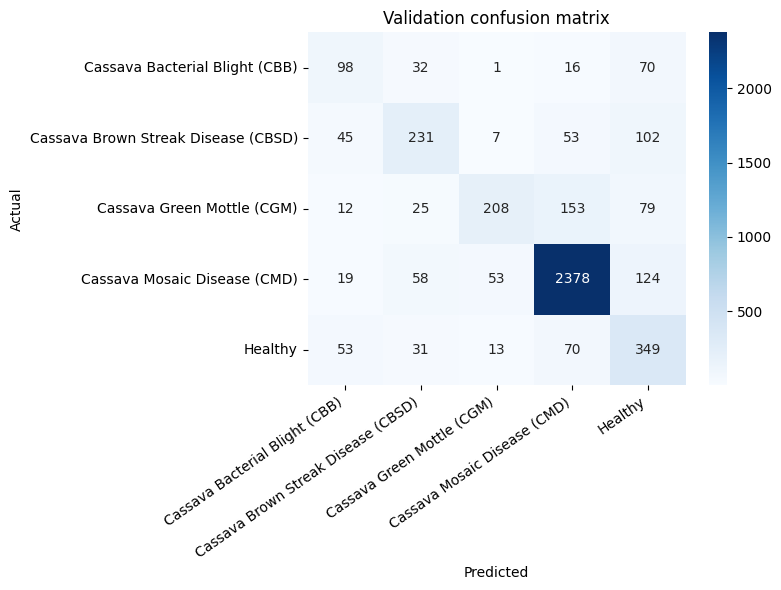

In [38]:
y_true = val_df.label.to_numpy()
y_prob = model.predict(val_sparse_ds.map(lambda x, y: x), verbose=1)
y_pred = np.argmax(y_prob, axis=1)

evaluation = {
    "accuracy": float(accuracy_score(y_true, y_pred)),
    "precision_macro": float(precision_score(y_true, y_pred, average="macro", zero_division=0)),
    "recall_macro": float(recall_score(y_true, y_pred, average="macro", zero_division=0)),
    "f1_macro": float(f1_score(y_true, y_pred, average="macro", zero_division=0)),
    "precision_weighted": float(precision_score(y_true, y_pred, average="weighted", zero_division=0)),
    "recall_weighted": float(recall_score(y_true, y_pred, average="weighted", zero_division=0)),
    "f1_weighted": float(f1_score(y_true, y_pred, average="weighted", zero_division=0))
}
display(pd.Series(evaluation, name="Validation metric").to_frame())
print(classification_report(
    y_true, y_pred, labels=list(range(NUM_CLASSES)),
    target_names=[CLASS_NAMES[i] for i in range(NUM_CLASSES)],
    zero_division=0
))
cm = confusion_matrix(y_true, y_pred, labels=list(range(NUM_CLASSES)))
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=list(CLASS_NAMES.values()),
            yticklabels=list(CLASS_NAMES.values()))
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Validation confusion matrix")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

## 12. Explore three image features

  0%|          | 0/600 [00:00<?, ?it/s]

,mean_brightness,contrast,mean_green
class_name,,,
Cassava Bacterial Blight (CBB),0.420,0.194,0.457
Cassava Brown Streak Disease (CBSD),0.446,0.185,0.491
Cassava Green Mottle (CGM),0.464,0.187,0.500
Cassava Mosaic Disease (CMD),0.454,0.183,0.493
Healthy,0.462,0.184,0.506


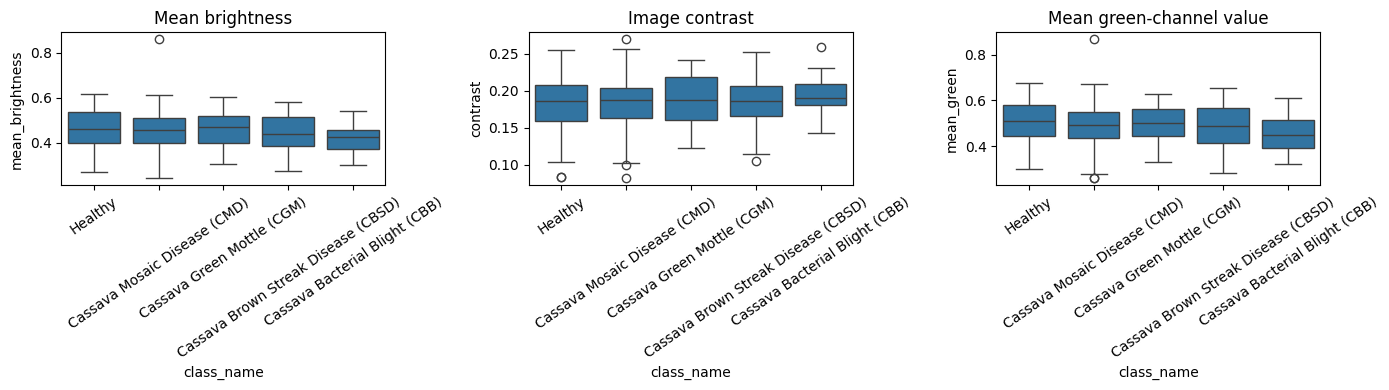

In [39]:
def extract_image_features(image_path):
    arr = np.asarray(
        Image.open(image_path).convert("RGB").resize((96, 96)),
        dtype=np.float32
    ) / 255.0
    gray = 0.299 * arr[:, :, 0] + 0.587 * arr[:, :, 1] + 0.114 * arr[:, :, 2]
    return {
        "mean_brightness": float(gray.mean()),
        "contrast": float(gray.std()),
        "mean_green": float(arr[:, :, 1].mean())
    }

feature_sample = labels_df.sample(min(600, len(labels_df)), random_state=SEED)
feature_rows = []
for row in tqdm(feature_sample.itertuples(index=False), total=len(feature_sample)):
    item = extract_image_features(TRAIN_DIR / row.image_id)
    item["class_name"] = CLASS_NAMES[int(row.label)]
    feature_rows.append(item)
features_df = pd.DataFrame(feature_rows)
display(features_df.groupby("class_name")[[
    "mean_brightness", "contrast", "mean_green"
]].mean().round(3))

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col, title in zip(
    axes,
    ["mean_brightness", "contrast", "mean_green"],
    ["Mean brightness", "Image contrast", "Mean green-channel value"]
):
    sns.boxplot(data=features_df, x="class_name", y=col, ax=ax)
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=35)
plt.tight_layout()
plt.show()

**Feature interpretation**

1. **Mean brightness:** average light level. It can change with lighting and camera exposure.
2. **Image contrast:** variation in pixel intensity. Leaf texture, spots, shadows and background can affect it.
3. **Mean green-channel value:** average green intensity. Leaf colour may help separate patterns, but it cannot diagnose disease by itself.

These are image statistics, not proof that a disease causes a certain colour or brightness.

## 14. Save both model formats and class metadata

In [40]:
# Save the same trained model in both requested formats.
model.save(str(KERAS_MODEL_PATH))
model.save(str(H5_MODEL_PATH))

with open(MODEL_DIR / "class_names.json", "w", encoding="utf-8") as f:
    json.dump({str(k): v for k, v in CLASS_NAMES.items()}, f, indent=2)

evaluation["validation_loss"] = float(model.evaluate(val_ds, verbose=0)[0])
with open(REPORT_DIR / "evaluation_metrics.json", "w", encoding="utf-8") as f:
    json.dump(evaluation, f, indent=2)

print("Saved Keras model:", KERAS_MODEL_PATH.resolve())
print("Saved H5 model:", H5_MODEL_PATH.resolve())
print("Saved class names:", (MODEL_DIR / "class_names.json").resolve())
print("Saved metrics:", (REPORT_DIR / "evaluation_metrics.json").resolve())

Saved Keras model: /kaggle/working/models/cassava_leaf_model.keras
Saved H5 model: /kaggle/working/models/cassava_leaf_model.h5
Saved class names: /kaggle/working/models/class_names.json
Saved metrics: /kaggle/working/reports/evaluation_metrics.json


## 15. Test prediction on one validation image

Actual class: Cassava Mosaic Disease (CMD)
Prediction: {'class_id': 3, 'class_name': 'Cassava Mosaic Disease (CMD)', 'confidence': 0.9943555593490601, 'probabilities': {'Cassava Bacterial Blight (CBB)': 0.0008756417664699256, 'Cassava Brown Streak Disease (CBSD)': 0.0024912820663303137, 'Cassava Green Mottle (CGM)': 0.0013317886041477323, 'Cassava Mosaic Disease (CMD)': 0.9943555593490601, 'Healthy': 0.0009458284475840628}}


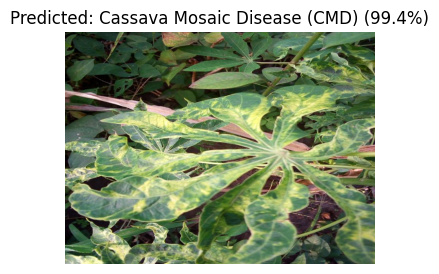

In [41]:
def predict_one_image(image_path, trained_model=None):
    trained_model = trained_model or model
    image = Image.open(image_path).convert("RGB").resize(
        (IMAGE_SIZE[1], IMAGE_SIZE[0]), Image.Resampling.BILINEAR
    )
    array = np.asarray(image, dtype=np.float32)[None, ...]
    probabilities = trained_model.predict(array, verbose=0)[0]
    predicted_id = int(np.argmax(probabilities))
    return {
        "class_id": predicted_id,
        "class_name": CLASS_NAMES[predicted_id],
        "confidence": float(probabilities[predicted_id]),
        "probabilities": {
            CLASS_NAMES[i]: float(probabilities[i]) for i in range(NUM_CLASSES)
        }
    }

sample = val_df.sample(1, random_state=SEED).iloc[0]
sample_path = TRAIN_DIR / sample.image_id
prediction = predict_one_image(sample_path)
print("Actual class:", CLASS_NAMES[int(sample.label)])
print("Prediction:", prediction)
plt.figure(figsize=(4, 4))
plt.imshow(Image.open(sample_path).convert("RGB"))
plt.title(f"Predicted: {prediction['class_name']} ({prediction['confidence']:.1%})")
plt.axis("off")
plt.show()

## 16. How to use the Python scripts

In [42]:
# Run these commands from the project root after the notebook has created src/ and models/.

# 1) Validate uploaded retraining images:
# python -m src.datacleaning data/retrain

# 2) Predict one image:
# python -m src.prediction data/test/example.jpg

# 3) Trigger retraining after placing labelled images into data/retrain/<class-name>/:
# python -m src.retrain --data data/retrain --epochs 3 --batch-size 16

# Retraining expects one folder per exact class name:
# data/retrain/
#   Cassava Bacterial Blight (CBB)/
#   Cassava Brown Streak Disease (CBSD)/
#   Cassava Green Mottle (CGM)/
#   Cassava Mosaic Disease (CMD)/
#   Healthy/

## 17. Important notes for the MLOps submission

- The notebook saves both `models/cassava_leaf_model.keras` and `models/cassava_leaf_model.h5`.
- The `.keras` file is the primary model used by `src/retrain.py`. The retraining script loads this saved model and fine-tunes it, rather than creating a new model from scratch.
- Upload new labelled images into `data/retrain/`, sorted into the five exact class folders. Then run the retraining command. This is the manual retraining trigger.
- The data cleaning script checks image files and class folder names. It reports invalid files and does not silently delete user data.
- The Kaggle competition test images have no labels. Use the stratified validation set for evaluation.
- Training time depends on the GPU, runtime, image storage and available memory. If memory is low, lower `BATCH_SIZE` to 8 or 16.
- If accuracy falls too much after reducing image size and model size, try `IMAGE_SIZE = (300, 300)` or EfficientNetB2, then compare validation metrics.
- Do not claim a specific accuracy until the notebook has completed on your machine.
- This model is an academic aid, not a replacement for an agricultural expert.

In [43]:
import shutil

# Create a temporary folder to gather only the directories you want
!mkdir -p /kaggle/working/project_export
!cp -r /kaggle/working/models /kaggle/working/project_export/
!cp -r /kaggle/working/reports /kaggle/working/project_export/
!cp -r /kaggle/working/src /kaggle/working/project_export/

# Compress into a single zip file
shutil.make_archive('/kaggle/working/cassava_project', 'zip', '/kaggle/working/project_export')
from IPython.display import FileLink
FileLink(r'cassava_project.zip')


/kaggle/working/cassava_project.zip